# Week 5 Task 2: Q-flux slab-ocean control

**Answer.** After a 4.5-year adjustment, the Q-flux control holds the ocean-mean SST within **0.05 K** of the
Week 4 climatology for 40 years. Over the last 20 years the residual drift is **−0.03 ± 0.01 K per decade** (2σ).
Locally, the annual-mean SST stays within ±0.7 K of the climatology in 95% of ocean cells (RMSE 0.39 K).
The one large error is the **seasonal cycle, which is about 40% too large**. The control inherits it from the
relaxed run that the Q-flux was derived from.

**How the runs were made** (all on the laptop CPU, about 7.5 min per model year; scripts in `nrp/`):

1. `make_slab_bc.py`: Week 4's `forcing_pd.nc` (SST, sea ice, land, CO2 = 420 ppmv) regridded to T31, so the slab
   reads exactly the boundary conditions Week 4 prescribed.
2. `run_slab.py relax`: jem's `earth-slab` on those boundary conditions and on Week 4's terrain, with the SST relaxed
   to the climatology (τ = 30 days), 2000–2010. Output is calendar-month means.
3. `make_qflux.py`: the Q-flux is the heat the relaxation added, computed exactly from the slab's implicit update
   and averaged over 2001–2010 by calendar month.
4. `run_slab.py qflux`: the free slab with that Q-flux, started from the relaxed run's final state, 2000–2039.
5. `summarize_slab.py`: annual means and the last-20-year monthly climatology, stored in `results/w5-task2_*.nc`.


In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

R = "../results/"
qf = xr.open_dataset(R + "w5-task2_qflux.nc")            # Q-flux file the control ran with, and the SST target
ra = xr.open_dataset(R + "w5-task2_relax_annual.nc")     # relaxed run (tau = 30 d), annual means
rc = xr.open_dataset(R + "w5-task2_relax_clim.nc")       # relaxed run, monthly climatology
qa = xr.open_dataset(R + "w5-task2_qcontrol_annual.nc")  # Q-flux control, annual means
qc = xr.open_dataset(R + "w5-task2_qcontrol_clim.nc")    # Q-flux control, monthly climatology (last 20 years)
w4 = xr.open_dataset(R + "w4-control_monthly.nc").sel(time=slice("2001", "2010"))   # Week 4 fixed-SST control
# Same T31 grid, but the latitudes differ in the last bits (1e-13); xarray aligns on exact
# labels and would silently drop most rows, so put Week 4 on the slab files' coordinates.
assert np.allclose(w4.lat, qa.lat) and np.allclose(w4.lon, qa.lon)
w4 = w4.assign_coords(lat=qa.lat, lon=qa.lon)
for d in (qf, ra, rc, qc):
    assert (d.lat == qa.lat).all() and (d.lon == qa.lon).all()

ocean = qa.ocean_mask == 1
w = np.cos(np.deg2rad(qa.lat))
def gmean(da, mask=None):
    """Area-weighted (cos lat) mean over lat/lon, optionally over a mask."""
    if mask is not None:
        da = da.where(mask)
    return da.weighted(w).mean(("lat", "lon"))
area = (w * xr.ones_like(qa.ocean_mask)) / (w * xr.ones_like(qa.ocean_mask)).sum() * 5.1e14   # m2 per cell
def ice_area(sic, hemi):
    return (sic.fillna(0) * area).where(qa.lat > 0 if hemi == "N" else qa.lat < 0).sum(("lat", "lon")) / 1e12  # million km2

target_ann = qf.sst_target.mean("time")
print("ocean cells:", int(ocean.sum()), " control years:", int(qa.year[0]), "-", int(qa.year[-1]),
      " climatology of the last 20 years:", qc.attrs["clim_years"])

ocean cells: 3051  control years: 2000 - 2039  climatology of the last 20 years: 2020-2039


## 1. The slab target is the Week 4 SST

In the Week 4 fixed-SST control the surface temperature of an all-ocean, ice-free cell is the prescribed SST (in a cell that is part land, `ts` blends land and sea). If `make_slab_bc.py` and the month-start interpolation are right, it equals the slab's target month by month.

In [2]:
w4_ts = w4.ts.groupby("time.month").mean().rename(month="time").assign_coords(time=qf.time)
pure = ocean & (qf.lsm == 0) & (qf.icec_max == 0)
d = (w4_ts - qf.sst_target).where(pure)
print(f"Week 4 ts - slab target, {int(pure.sum())} all-ocean ice-free cells: max |diff| {float(abs(d).max()):.3f} K, "
      f"mean {float(gmean(d).mean()):+.4f} K")

Week 4 ts - slab target, 1895 all-ocean ice-free cells: max |diff| 0.088 K, mean -0.0017 K


The two agree to 0.09 K in every month, so the slab's target is the Week 4 SST. Records at month starts in both jcm and jem, so there is no half-month lag (the open question from Task 1).

## 2. The Q-flux

ocean-mean Q -13.44 W m-2;  cells that ever have ice contribute -2.72
relaxed run, ocean-mean upward surface flux -9.28 W m-2
ocean-mean Q as a global sink: -4.87 PW; peak implied OHT +1.11 PW at 17N, -0.37 PW at 43N


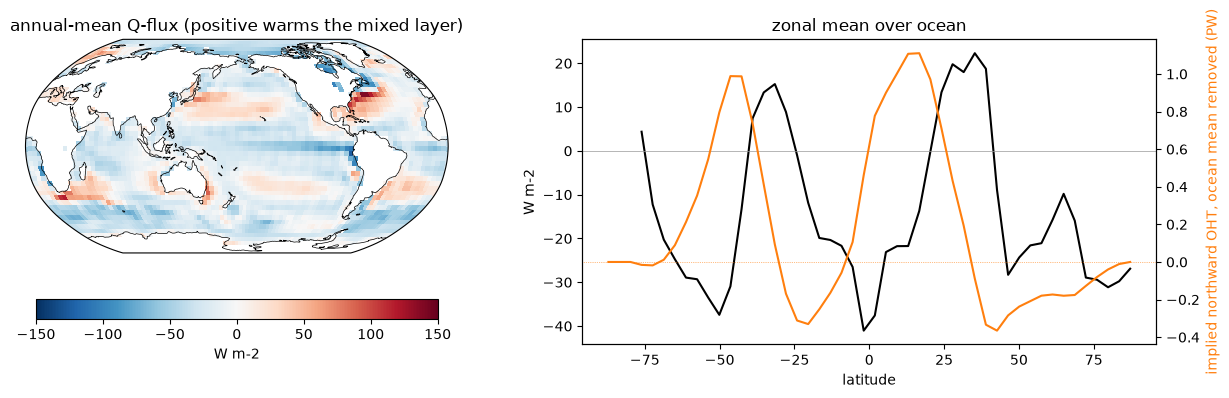

In [3]:
q_ann = qf.qflux_monthly_mean.mean("time").where(ocean)
print(f"ocean-mean Q {float(gmean(q_ann)):+.2f} W m-2;  cells that ever have ice contribute "
      f"{float(gmean(q_ann.where(rc.sic.max('month') > 0.01).fillna(0), ocean)):+.2f}")
print(f"relaxed run, ocean-mean upward surface flux {float(gmean(rc.hfds_up.mean('month'))):+.2f} W m-2")

fig = plt.figure(figsize=(13, 4))
ax = fig.add_subplot(1, 2, 1, projection=ccrs.Robinson(central_longitude=180))
m = q_ann.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r", vmin=-150, vmax=150, add_colorbar=False)
ax.coastlines(lw=0.5); ax.set_title("annual-mean Q-flux (positive warms the mixed layer)")
plt.colorbar(m, ax=ax, orientation="horizontal", shrink=0.7, label="W m-2")
ax = fig.add_subplot(1, 2, 2)
zq = q_ann.mean("lon")
ax.plot(qf.lat, zq, "k")
ax.axhline(0, c="0.6", lw=0.5); ax.set_xlabel("latitude"); ax.set_ylabel("W m-2"); ax.set_title("zonal mean over ocean")
# Implied northward ocean heat transport: integrate the zonal-total Q from the south pole, after
# removing the ocean mean (-13 W m-2, a sink to the "deep ocean" that no transport can supply).
q_anom = (q_ann - gmean(q_ann)).where(ocean)
qz = (q_anom.fillna(0) * area).sum("lon").values
oht = -np.cumsum(qz) / 1e15
print(f"ocean-mean Q as a global sink: {float(gmean(q_ann)) * float((area * ocean).sum()) / 1e15:+.2f} PW; "
      f"peak implied OHT {oht.max():+.2f} PW at {float(qf.lat[oht.argmax()]):.0f}N, {oht.min():+.2f} PW at {float(qf.lat[oht.argmin()]):.0f}N")
ax2 = ax.twinx(); ax2.plot(qf.lat, oht, "C1"); ax2.set_ylabel("implied northward OHT, ocean mean removed (PW)", color="C1"); ax2.axhline(0, c="C1", lw=0.5, ls=":")
plt.tight_layout(); plt.savefig("../figures/week5_qflux.png", dpi=150); plt.show()

**The Q-flux is a flux correction, not an ocean heat transport.** Its ocean mean is −13.4 W m⁻² (−4.9 PW), a heat sink that balances the +5.4 W m⁻² TOA imbalance SPEEDY has at observed SST. The surface flux into the ocean is 9.3 W m⁻². The other 4.2 W m⁻² is the heat the slab adds when it clamps SST at freezing, so cells with sea ice contribute −2.7 W m⁻² to the mean.
With the mean removed, the implied transport is 1.1 PW northward at 17°N, which is realistic. But it runs equatorward near 45°N and 45°S, because Q is negative over the subpolar oceans. That pattern comes from SPEEDY's surface-flux biases, not from real ocean dynamics.

## 3. Drift of the Q-flux control

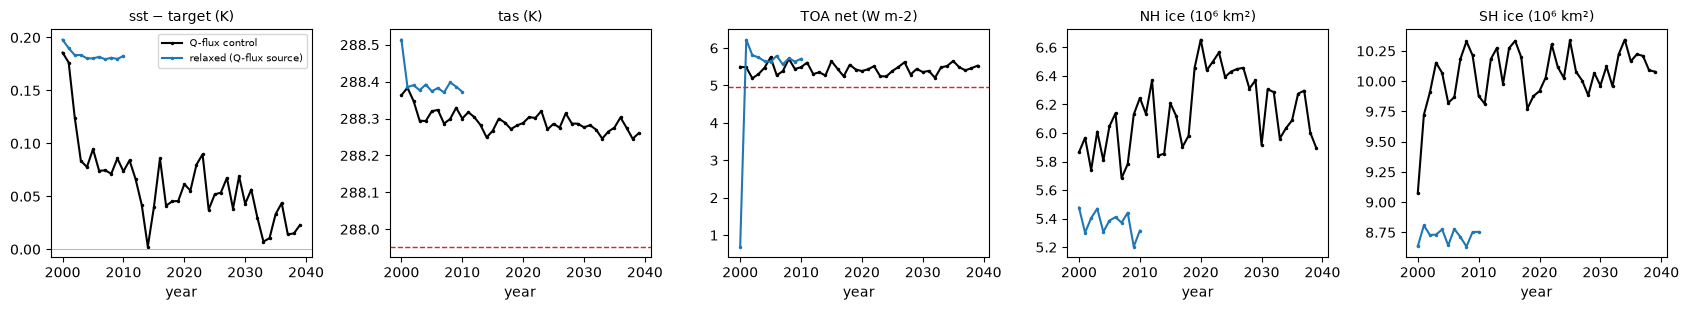

In [4]:
sst_off = gmean(qa.sst - target_ann, ocean)
ts = xr.Dataset({
    "sst − target (K)": sst_off,
    "tas (K)": gmean(qa.tas),
    "TOA net (W m-2)": gmean(qa.rtnt),
    "NH ice (10⁶ km²)": ice_area(qa.sic, "N"),
    "SH ice (10⁶ km²)": ice_area(qa.sic, "S"),
})
rel = {"sst − target (K)": gmean(ra.sst - target_ann, ocean), "tas (K)": gmean(ra.tas),
       "TOA net (W m-2)": gmean(ra.rtnt), "NH ice (10⁶ km²)": ice_area(ra.sic, "N"),
       "SH ice (10⁶ km²)": ice_area(ra.sic, "S")}
w4ref = {"tas (K)": float(gmean(w4.tas).mean()), "TOA net (W m-2)": float(gmean(w4.rtnt).mean())}

fig, axs = plt.subplots(1, 5, figsize=(17, 3.2))
for ax, k in zip(axs, ts):
    ax.plot(qa.year, ts[k], "k.-", ms=3, label="Q-flux control")
    ax.plot(ra.year, rel[k], "C0.-", ms=3, label="relaxed (Q-flux source)")
    if k in w4ref:
        ax.axhline(w4ref[k], c="C3", ls="--", lw=1, label="Week 4 fixed SST")
    ax.set_title(k, fontsize=10); ax.set_xlabel("year")
axs[0].axhline(0, c="0.6", lw=0.5); axs[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig("../figures/week5_qflux_control_drift.png", dpi=150); plt.show()

In [5]:
from scipy.optimize import curve_fit

yrs = (qa.year - qa.year[0]).values.astype(float)
y = sst_off.values
f = lambda t, a, b, tau: a + b * np.exp(-t / tau)
(a_, b_, tau_), cov = curve_fit(f, yrs, y, p0=(y[-10:].mean(), y[0] - y[-10:].mean(), 5.0))
print(f"ocean SST - target = {a_:+.3f} {b_:+.3f} exp(-t/{tau_:.1f} yr)   (fit; t from {int(qa.year[0])})")

def trend(series, n=20):
    """OLS trend of the last n years in units per decade, with lag-1 adjusted standard error."""
    s = series[-n:]; t = np.arange(n)
    p = np.polyfit(t, s, 1); res = s - np.polyval(p, t)
    r1 = np.corrcoef(res[:-1], res[1:])[0, 1]
    neff = n * (1 - r1) / (1 + r1) if r1 > 0 else n
    se = np.sqrt(np.sum(res**2) / (neff - 2) / np.sum((t - t.mean())**2))
    return 10 * p[0], 10 * se

for k in ts:
    tr, se = trend(ts[k].values)
    last = ts[k].values[-20:]
    print(f"{k:18s} last 20 yr mean {last.mean():8.3f} (SD {last.std(ddof=1):.3f}),  trend {tr:+.3f} ± {2*se:.3f} per decade")

ocean SST - target = +0.044 +0.137 exp(-t/4.5 yr)   (fit; t from 2000)
sst − target (K)   last 20 yr mean    0.044 (SD 0.023),  trend -0.029 ± 0.012 per decade
tas (K)            last 20 yr mean  288.281 (SD 0.020),  trend -0.021 ± 0.013 per decade
TOA net (W m-2)    last 20 yr mean    5.427 (SD 0.120),  trend +0.064 ± 0.102 per decade
NH ice (10⁶ km²)   last 20 yr mean    6.281 (SD 0.224),  trend -0.303 ± 0.107 per decade
SH ice (10⁶ km²)   last 20 yr mean   10.107 (SD 0.134),  trend +0.053 ± 0.120 per decade


**Drift.** Once the relaxation is removed, the control cools by 0.14 K relative to the relaxed run, with an e-folding time of **4.5 years**. That matches the slab's expected 3–6 years. Sea ice grows by about 16% in each hemisphere (NH 5.4 → 6.3, SH 8.7 → 10.1 million km²), and most of the cooling is poleward of 40°. This is the ice-albedo feedback acting freely for the first time.
After about 2010 the run is in equilibrium:
- Ocean SST sits **0.044 K** above the climatology (SD 0.023 K between years).
- TOA net is steady at +5.4 W m⁻² (no significant trend).
- The last-20-year SST trend, −0.029 ± 0.012 K per decade, is statistically detectable but small: 0.3 K per century, against the 2–4 K CO₂ signal of Task 3.
- NH sea ice has decadal swings of ±0.4 million km² with no clear direction, which is internal variability.

## 4. Equilibrium state against the climatology

control (last 20 yr) minus target: ocean mean +0.045 K, RMSE 0.387 K, 95% of cells within ±0.72 K
relaxed run minus target:          ocean mean +0.185 K, RMSE 0.418 K
seasonal range (max - min month) minus target's: control +1.641 K, relaxed run +1.703 K (ocean means)


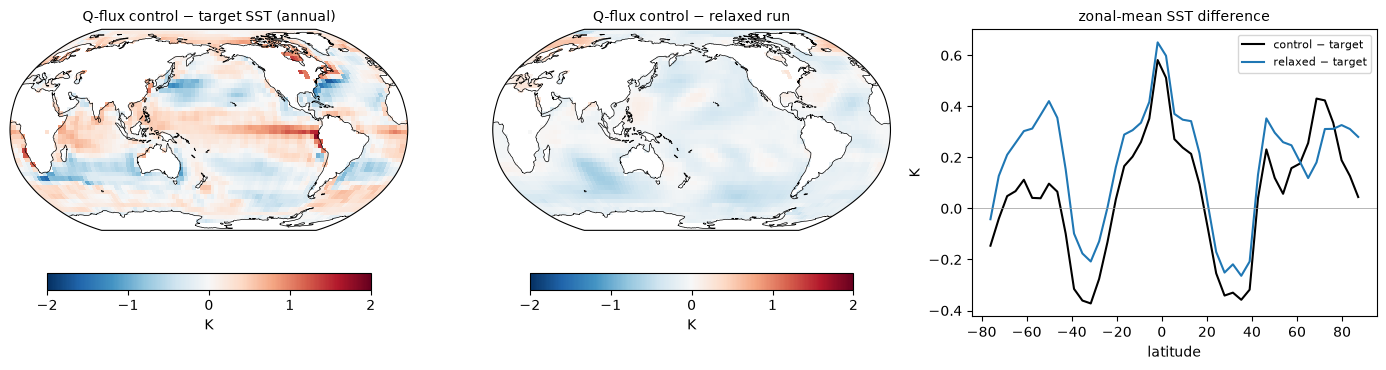

In [6]:
bias = (qc.sst.mean("month") - target_ann).where(ocean)
bias_rel = (rc.sst.mean("month") - target_ann).where(ocean)
seas = (qc.sst.max("month") - qc.sst.min("month")) - (qf.sst_target.max("time") - qf.sst_target.min("time")).rename(None)
print(f"control (last 20 yr) minus target: ocean mean {float(gmean(bias)):+.3f} K, RMSE {float(np.sqrt(gmean(bias**2))):.3f} K, "
      f"95% of cells within ±{float(abs(bias).quantile(0.95)):.2f} K")
print(f"relaxed run minus target:          ocean mean {float(gmean(bias_rel)):+.3f} K, RMSE {float(np.sqrt(gmean(bias_rel**2))):.3f} K")
seas_rel = (rc.sst.max("month") - rc.sst.min("month")) - (qf.sst_target.max("time") - qf.sst_target.min("time")).rename(None)
print(f"seasonal range (max - min month) minus target's: control {float(gmean(seas.where(ocean))):+.3f} K, "
      f"relaxed run {float(gmean(seas_rel.where(ocean))):+.3f} K (ocean means)")

fig = plt.figure(figsize=(14, 3.8))
for i, (fld, title) in enumerate([(bias, "Q-flux control − target SST (annual)"),
                                  (qc.sst.mean("month") - rc.sst.mean("month"), "Q-flux control − relaxed run")]):
    ax = fig.add_subplot(1, 3, i + 1, projection=ccrs.Robinson(central_longitude=180))
    m = fld.where(ocean).plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r", vmin=-2, vmax=2, add_colorbar=False)
    ax.coastlines(lw=0.5); ax.set_title(title, fontsize=10)
    plt.colorbar(m, ax=ax, orientation="horizontal", shrink=0.8, label="K")
ax = fig.add_subplot(1, 3, 3)
ax.plot(qa.lat, bias.mean("lon"), "k", label="control − target")
ax.plot(qa.lat, bias_rel.mean("lon"), "C0", label="relaxed − target")
ax.axhline(0, c="0.6", lw=0.5); ax.set_xlabel("latitude"); ax.set_ylabel("K"); ax.legend(fontsize=8)
ax.set_title("zonal-mean SST difference", fontsize=10)
plt.tight_layout(); plt.savefig("../figures/week5_qflux_control_bias.png", dpi=150); plt.show()

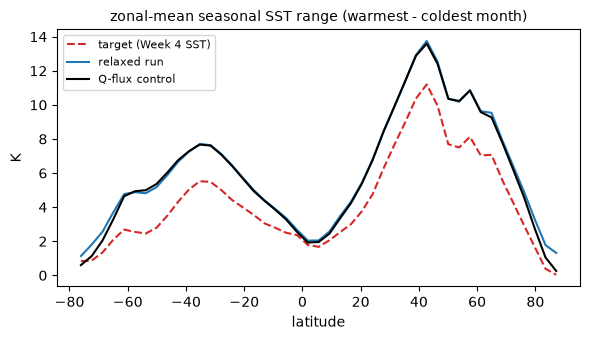

In [7]:
rng = lambda d, dim: (d.max(dim) - d.min(dim)).where(ocean).mean("lon")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(qa.lat, rng(qf.sst_target, "time"), "C3--", label="target (Week 4 SST)")
ax.plot(qa.lat, rng(rc.sst, "month"), "C0", label="relaxed run")
ax.plot(qa.lat, rng(qc.sst, "month"), "k", label="Q-flux control")
ax.set_xlabel("latitude"); ax.set_ylabel("K"); ax.legend(fontsize=8)
ax.set_title("zonal-mean seasonal SST range (warmest - coldest month)", fontsize=10)
plt.tight_layout(); plt.savefig("../figures/week5_qflux_control_seasonal.png", dpi=150); plt.show()

**Annual-mean bias.** The control is within 0.05 K of the climatology in the ocean mean and within ±0.72 K in 95% of cells. The largest errors are:
- warm in the equatorial cold tongue (+1 to +2 K in the east Pacific and Atlantic);
- cold south of the Kuroshio and Gulf Stream (−1 K);
- cold along 40–60°S.

The relaxed run has the same pattern, slightly warmer everywhere. The middle map shows the control differs from it by only a few tenths of a K.

**Seasonal cycle.** The seasonal SST range is too large by 1.6 K on average and by up to 2.5 K at 40°N and 30°S. The annual-harmonic amplitude over ice-free ocean is 3.0 K, against 2.1 K in the climatology, and the cycle peaks about 5 days early. The relaxed run has the same excess (+1.7 K), so the cause is not the Q-flux method. The slab's fixed 40–60 m mixed layer, driven by SPEEDY's seasonal surface fluxes, wants a larger cycle, and 30-day relaxation is too weak to stop it. The Q-flux reproduces the relaxed run's cycle, as designed. A Q-flux derived from a stronger relaxation, or from a fixed-SST run's surface fluxes, would fix this.


In [8]:
rows = {
    "Week 4 fixed SST (2001-10)": dict(tas=gmean(w4.tas).mean(), pr=gmean(w4.pr).mean() * 86400, toa=gmean(w4.rtnt).mean(), sst=np.nan),
    f"relaxed slab ({ra.year.values[1]}-{ra.year.values[-1]})": dict(tas=gmean(ra.tas.isel(year=slice(1, None))).mean(), pr=gmean(ra.pr.isel(year=slice(1, None))).mean() * 86400,
                                                                      toa=gmean(ra.rtnt.isel(year=slice(1, None))).mean(), sst=gmean(ra.sst.isel(year=slice(1, None)), ocean).mean()),
    f"Q-flux control ({qc.attrs['clim_years']})": dict(tas=gmean(qc.tas.mean("month")), pr=gmean(qc.pr.mean("month")) * 86400,
                                                       toa=gmean(qc.rtnt.mean("month")), sst=gmean(qc.sst.mean("month"), ocean)),
}
print(f"{'':28s} {'tas K':>8s} {'pr mm/d':>8s} {'TOA W m-2':>10s} {'ocean SST K':>12s}")
for k, r in rows.items():
    print(f"{k:28s} {float(r['tas']):8.2f} {float(r['pr']):8.3f} {float(r['toa']):+10.2f} {float(r['sst']):12.2f}")
print(f"{'slab target (Week 4 SST)':28s} {'':8s} {'':8s} {'':10s} {float(gmean(target_ann, ocean)):12.2f}")

                                tas K  pr mm/d  TOA W m-2  ocean SST K
Week 4 fixed SST (2001-10)     287.95    2.922      +4.95          nan
relaxed slab (2001-2010)       288.38    2.977      +5.75       291.76
Q-flux control (2020-2039)     288.28    2.972      +5.46       291.62
slab target (Week 4 SST)                                        291.57


**Against Week 4.** The slab control is 0.33 K warmer in global-mean `tas` than the fixed-SST run, even though its ocean-mean SST is only 0.05 K warmer. We have not tracked down where this difference comes from (open question). Its TOA imbalance is also 0.5 W m⁻² larger. Precipitation is within 2%.

## For Task 3 (abrupt 2×/4×CO₂)

- **Branch point:** `~/jcm-runs/w5-qcontrol/checkpoint` (14 MB, 2040-01-01). Rerunning `run_slab.py qflux` with a CO₂ `--bc` and `--init` will **not** work, because `--init` expects a relaxed run. To branch from the control, copy its checkpoint into the new run directory.
- **Baseline:** use the control's last 20 years (2020–2039). The control's drift, 0.03 K per decade, is negligible next to the response.
- **Land:** earth-slab relaxes land temperature to climatology with `tdland = 1 day` (SPEEDY's default is 40 days). Land is therefore effectively prescribed and will hardly warm under CO₂. This should be changed or flagged before computing ECS.
- **CO₂:** check that a restored checkpoint takes the new file's `co2` and does not keep 420 ppmv from the carry.
